In [4]:
import sys
import os
import numpy as np
import pandas as pd

from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [5]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [6]:
file_ids = list(range(0, 33+1))
# file_ids = [0,   # minrevs
# 			1,   # minswitch
# 			7,   # maxswitch
# 			11,  # median
# 			12,  # maxrevs
# 			17,  # mean
# 			19,  # paper
# 			21]  # clean
# file_ids = [19]
plot_id = 19

bhl_selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

dims = 2
dims_preca = 5

In [7]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(file_ids, filenames,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymographs) = read_utils.get_datas(path, file_ids)

# clear nan values
for i in range(len(file_ids)):
	mask = eigenworms[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	kymographs[i] = kymographs[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# preprocess
pass

In [8]:
for idx in range(len(discrete_states)):
	discrete_states[idx]['FWD'] = np.logical_or(
		discrete_states[idx]['FWD'].values,
		discrete_states[idx]['SLOWING'].values
	).astype(np.intp)
	discrete_states[idx] = discrete_states[idx].drop('SLOWING', axis=1)

	discrete_states[idx]['UNKNOWN'] = np.logical_or(
		discrete_states[idx]['UNKNOWN'].values,
		discrete_states[idx]['TRACKING_FAILURE'].values
	).astype(np.intp)
	discrete_states[idx] = discrete_states[idx].drop('TRACKING_FAILURE', axis=1)

	discrete_states[idx] = discrete_states[idx].reindex(columns=['FWD', 'REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE', 'UNKNOWN'])

In [9]:
plot_idx = file_ids.index(plot_id)

In [10]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces,
																	[ds[bhl_selection] for ds in discrete_states],
																	scale=False,
																	n_cv=dims, n_pc=dims_preca)

In [11]:
# for file_id in range(len(file_ids)):
# 	corrs = [
# 		np.corrcoef(modes_manifold[file_ids.index(file_id)].values[:, i], modes_manifold_b[file_ids.index(file_id)].values[:, i])[0, 1] for i in range(modes_manifold[file_ids.index(file_id)].values.shape[1])
# 	]
# 	print(f'{filenames[file_ids.index(file_id)]}')
# 	for i, corr in enumerate(corrs):
# 		print(f'\tCV {i}: {corr:.2f}')

In [12]:
save = True

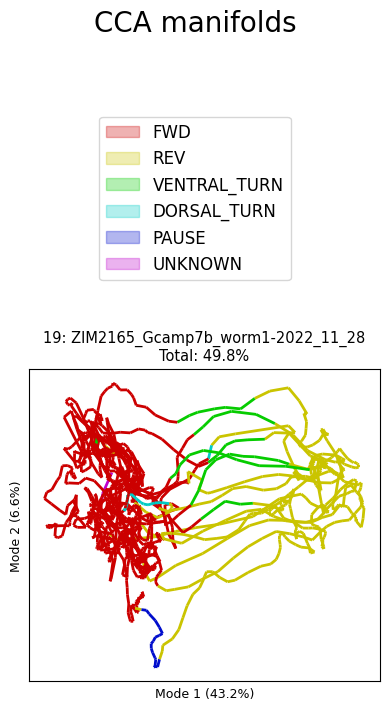

49.8%


In [13]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold,
						  discrete_states,
						  [vx[:2] for vx in vars_expl_mans], None, #[vx[:2] for vx in vars_expl_mans_rs] if dims_preca > 0 else
						  title='CCA manifolds', top_space=3.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-CCA' if save else None)

In [14]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 							 modes_manifold, discrete_states,
# 							 [vx[:3] for vx in vars_expl_mans], [vx[:3] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
# 							 title='CCA manifolds', top_space=3.5,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-CCA_3d' if save else None)

In [15]:
# plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 								 modes_manifold, discrete_states,
# 								 [vx[:3] for vx in vars_expl_mans], [vx[:3] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
# 								 titles=['CCA manifolds'] * len(file_ids), top_space=3.5, animate=True,
# 								 save_path=f'../../out/plots/manifolds/{dims}-dim-CCA_3d' if save else None)

In [16]:
for i, trace in enumerate(traces):
	print(np.mean(trace.values, axis=0))

[ 6.10952614e-03 -1.30114644e-02  1.76469675e-01  2.49310315e-01
 -2.82492632e-02 -1.66925802e-02  1.46405163e-01  1.20141746e-03
  5.45032072e-02  8.01172306e-02  9.38201535e-03 -5.62849767e-03
 -3.02813765e-02  9.89400996e-03  3.82669316e-02 -3.25401765e-04
  3.53853372e-02  5.39965887e-02  3.76975920e-02  4.45407776e-02
  7.95361816e-03  7.94610962e-03  9.31114288e-03  8.74235883e-03
 -2.44459271e-02 -6.69393833e-03 -1.30088193e-02 -2.38264416e-02
  1.81244814e-02  3.87596048e-03  1.92805707e-02  1.39761371e-02
  1.21765779e-02  3.31308732e-03  1.07190033e-02  2.77556352e-03
  5.80024831e-03  3.05931224e-03  8.87820789e-03  1.48242307e-02
  1.01686881e-02  5.92105704e-03  1.66454946e-02 -1.59383635e-03
  9.70601785e-04 -7.35352290e-03  4.43282878e-03  4.42544491e-03
  2.50908547e-03 -3.66346699e-03  2.69710548e-03  3.33012713e-02
  2.93359489e-03  5.81231525e-03  9.09687656e-03  4.81746206e-02
  5.66771608e-03  1.31229711e-02 -9.20908299e-04  1.48686539e-02
  1.59715795e-02 -1.51840

In [17]:
traces_residual = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]

for i, trace in enumerate(traces_residual):
	print(np.mean(trace.values, axis=0))

[-6.92640639e-18  1.06560098e-17 -2.51481832e-16  1.12953704e-16
 -1.27872118e-17  3.19680295e-18  1.35331325e-16  1.59840148e-18
  2.23776207e-17  2.77056256e-17  6.66000615e-18  5.32800492e-18
 -2.13120197e-17  0.00000000e+00  1.91808177e-17 -2.13120197e-18
 -2.98368275e-17  2.55744236e-17 -6.81984629e-17 -6.60672610e-17
  1.94472179e-17  1.99800184e-18  3.19680295e-18  2.13120197e-18
  2.13120197e-17 -9.85680910e-18  8.52480787e-18  6.39360590e-18
  2.23776207e-17 -1.38528128e-17 -1.70496157e-17  5.86080541e-18
 -1.91808177e-17 -7.99200738e-18 -1.11888103e-17  3.59640332e-18
  0.00000000e+00  1.17216108e-17  5.86080541e-18 -1.91808177e-17
  1.70496157e-17 -5.32800492e-18 -2.13120197e-18  6.92640639e-18
  2.55744236e-17  2.13120197e-18 -4.26240393e-18 -1.59840148e-17
  0.00000000e+00 -1.01232093e-17 -8.52480787e-18  2.98368275e-17
 -1.30536120e-17 -1.75824162e-17 -3.46320320e-18 -4.26240393e-17
 -1.33200123e-18  1.35864125e-17 -1.01232093e-17  7.45920688e-18
  4.90176452e-17  2.13120

# autostereogram

In [18]:
# # Rotate modes_manifold by ﷿﷿﷿﷿﷿﷿5 degrees around the second axis (y-axis)
# # and 20 degrees around the first axis (x-axis)
# angle_y_deg = 10
# angle_x_deg = 20
# angle_y_rad = np.deg2rad(angle_y_deg)
# angle_x_rad = np.deg2rad(angle_x_deg)
#
# # Rotation matrix for x-axis (3D)
# R_x = np.array([
#     [1, 0, 0],
#     [0, np.cos(angle_x_rad), -np.sin(angle_x_rad)],
#     [0, np.sin(angle_x_rad), np.cos(angle_x_rad)]
# ])
#
# # Rotation matrices for y-axis (3D)
# R_y_left = np.array([
#     [np.cos(angle_y_rad), 0, np.sin(angle_y_rad)],
#     [0, 1, 0],
#     [-np.sin(angle_y_rad), 0, np.cos(angle_y_rad)]
# ])
# R_y_right = np.array([
#     [np.cos(-angle_y_rad), 0, np.sin(-angle_y_rad)],
#     [0, 1, 0],
#     [-np.sin(-angle_y_rad), 0, np.cos(-angle_y_rad)]
# ])
#
# # Combined rotation: first x, then y
# R_left = R_x @ R_y_left
# R_right = R_x @ R_y_right
#
# modes_manifold_l = [m @ R_left for m in modes_manifold]
# modes_manifold_r = [m @ R_right for m in modes_manifold]


In [19]:
# plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 						  modes_manifold_l,
# 						  discrete_states,
# 						  [vx[:2] for vx in vars_expl_mans], [vx[:2] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
# 						  title='CCA manifolds', top_space=3.5,
# 						  save_path=f'../../out/plots/manifolds/{dims}-dim-CCA_autostereo_l' if save else None)

In [20]:
# plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 						  modes_manifold_r,
# 						  discrete_states,
# 						  [vx[:2] for vx in vars_expl_mans], [vx[:2] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
# 						  title='CCA manifolds', top_space=3.5,
# 						  save_path=f'../../out/plots/manifolds/{dims}-dim-CCA_autostereo_r' if save else None)